# Informe Etapa 2: Analisis y visualización de los graficos

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import json
from datetime import datetime, timezone
from pathlib import Path

from catalogo import (
    leer_satelites,
    anio_lanzamiento,
    grupo,
    lanzamientos_por_anio,
    contar_por_grupo
)
from satelite import (
    Satelite,
    crear_satelites
)
from analisis import resumen_por_grupo
from funciones_base import epoch_medio
from graficos import (
    graficar_lanzamientos,
    graficar_lanzamientos_apilados,
    graficar_altitud_media,
    graficar_altitudes_leo,
    graficar_altitudes_log,
    graficar_inclinaciones,
)




In [16]:
RUTA_PROYECTO = Path(".")
ruta_datos = RUTA_PROYECTO / "datos" / "satelites.json"

registros = leer_satelites(ruta_datos)
momento = epoch_medio(registros)
satelites = crear_satelites(registros, momento)

print("Cantidad de registros: ", len(registros))
print("Cantidad de objetos Satelite: ",len(satelites))

Cantidad de registros:  16822
Cantidad de objetos Satelite:  16822


## 1. Lanzamientos por año (1990-2026)

In [12]:
lanzamientos = lanzamientos_por_anio(registros)

registros_starlink = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) == "Starlink"
]
registros_resto = [
    reg for reg in registros
    if grupo(reg["OBJECT_NAME"]) != "Starlink"
]
lanzamientos_starlink = lanzamientos_por_anio(registros_starlink)
lanzamientos_resto = lanzamientos_por_anio(registros_resto)

lanzamientos_90_26 = {a: c for a, c in lanzamientos.items() if 1990 <= a <= 2026}
starlink_90_26 = {a: c for a, c in lanzamientos_starlink.items() if 1990 <= a <= 2026}
resto_90_26 = {a: c for a,c in lanzamientos_resto.items() if 1990 <= a <= 2026}

print("Satélites Starlink: ", len(registros_starlink))
print("Resto de satélites: ", len(registros_resto))

Satélites Starlink:  11160
Resto de satélites:  5662


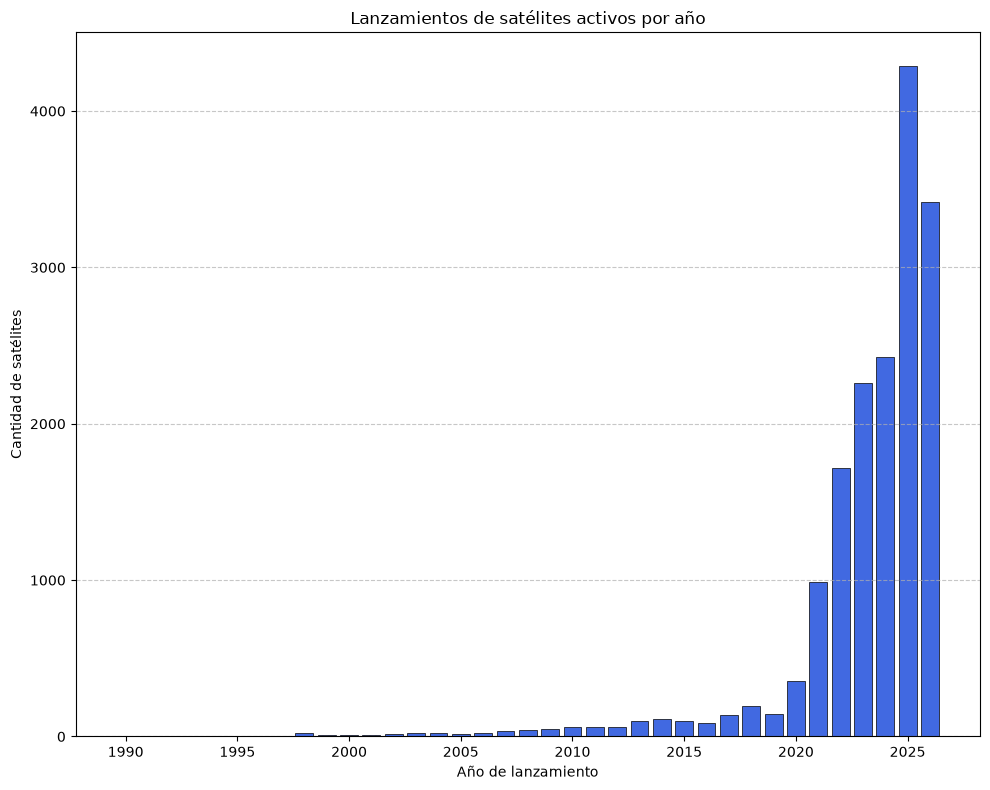

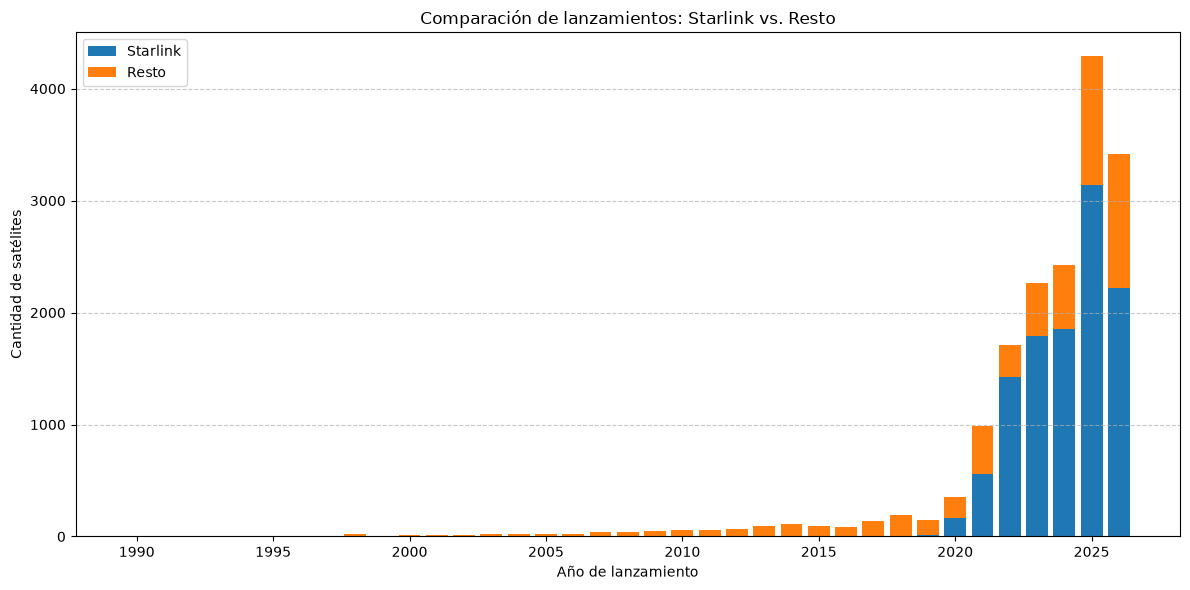

In [14]:
graficar_lanzamientos(lanzamientos_90_26)
graficar_lanzamientos_apilados(
    starlink_90_26,
    resto_90_26
)